<a href="https://colab.research.google.com/github/s-fridman/online-store-sales-analytics-project/blob/main/Online_Store_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[Dashboard](https://public.tableau.com/views/Sessions_17938809790950/SalesCustomerBehaviorDashboard?:language=en-US&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

In [ ]:
from google.colab import auth
auth.authenticate_user()

In [ ]:
from google.cloud import bigquery

client = bigquery.Client(project="data-analytics-mate")

query = """
WITH session_params AS (
  SELECT ga_session_id, continent, country, device, browser,
  mobile_model_name, operating_system, COALESCE(language, 'Unknown') as browser_language,
  medium as traffic_source, channel as traffic_channel
  FROM `DA.session_params`
),
orders AS (
  SELECT o.ga_session_id, p.category as product_category, p.name as product_name,
  p.price as product_price, p.short_description as product_description
  FROM `DA.order` o
  LEFT JOIN `DA.product` p
  ON o.item_id = p.item_id
),
accounts AS (
  SELECT acs.ga_session_id, a.id as account_id,
  a.is_verified, a.is_unsubscribed
  FROM `DA.account_session` acs
  LEFT JOIN `DA.account` a
  ON acs.account_id = a.id
)

SELECT s.date as session_date, s.ga_session_id as session_id,
sp.continent, sp.country, sp.device, sp.browser, sp.mobile_model_name,
sp.operating_system, sp.browser_language, sp.traffic_source, sp.traffic_channel,
a.account_id,
CASE WHEN a.account_id IS NULL THEN 'Guest'
     WHEN a.is_verified = 1 THEN 'Verified'
     ELSE 'Not verified' END as account_status,
CASE WHEN a.account_id IS NULL THEN 'Guest'
     WHEN a.is_unsubscribed = 1 THEN 'Unsubscribed'
     ELSE 'Subscribed' END as subscription_status,
o.product_category, o.product_name, o.product_price, o.product_description
FROM `DA.session` s
LEFT JOIN session_params sp
ON s.ga_session_id = sp.ga_session_id
LEFT JOIN orders o
ON s.ga_session_id = o.ga_session_id
LEFT JOIN accounts a
ON s.ga_session_id = a.ga_session_id
"""

query_job = client.query(query)
results = query_job.result()

The table 'session' was used as the main table, and all other tables were joined with LEFT JOIN to keep all sessions. The columns 'is_verified' and 'is_unsubscribed' were renamed to 'account_status' and 'subscription_status', and their values were changed from 1 and 0 to text labels: 'Verified' / 'Not verified' and 'Subscribed' / 'Unsubscribed'. Missing values (sessions without an account) were marked as 'Guest'. Other cleaning was done in Python.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import normaltest, shapiro, spearmanr, pearsonr, mannwhitneyu, wilcoxon, ttest_ind, kruskal, friedmanchisquare
from statsmodels.stats.proportion import proportions_ztest

orange_palette = ['#FFE5CC', '#FFB266', '#FF9933', '#FF8000', '#CC6600', '#994C00']
green_orng_palette = ['#d95301', '#fa713f', '#ffa300', '#ffbe63', '#cbb927', '#77722e']
sns.set_theme(style='whitegrid', palette=orange_palette)

In [ ]:
df = results.to_dataframe()

In [ ]:
display(df.head())
df.info()

,session_date,session_id,continent,country,device,browser,mobile_model_name,operating_system,browser_language,traffic_source,traffic_channel,account_id,account_status,subscription_status,product_category,product_name,product_price,product_description
0,2020-11-01,5760483956,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,<Other>,Paid Search,<NA>,Guest,Guest,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,7115337200,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,organic,Organic Search,<NA>,Guest,Guest,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3978035233,Europe,Norway,mobile,Chrome,<Other>,Web,zh,(none),Direct,<NA>,Guest,Guest,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,2020-11-01,9648986282,Africa,Nigeria,mobile,Chrome,<Other>,Android,es-es,(none),Direct,<NA>,Guest,Guest,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,2020-11-01,4393441533,Asia,China,desktop,Chrome,Chrome,Windows,en-us,(none),Direct,<NA>,Guest,Guest,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   session_date         349545 non-null  dbdate 
 1   session_id           349545 non-null  Int64  
 2   continent            349545 non-null  object 
 3   country              349545 non-null  object 
 4   device               349545 non-null  object 
 5   browser              349545 non-null  object 
 6   mobile_model_name    349545 non-null  object 
 7   operating_system     349545 non-null  object 
 8   browser_language     349545 non-null  object 
 9   traffic_source       349545 non-null  object 
 10  traffic_channel      349545 non-null  object 
 11  account_id           27945 non-null   Int64  
 12  account_status       349545 non-null  object 
 13  subscription_status  349545 non-null  object 
 14  product_category     33538 non-null   object 
 15  product_name     

# Data overview and cleaning

In [ ]:
df['traffic_source'].value_counts()

,count
traffic_source,
organic,119024
(none),81382
referral,61437
<Other>,50593
(data deleted),21859
cpc,15250


Columns 'name' and 'medium' contain similar information about traffic, so they were compared. It was found that '(none)' in medium is the same as '(direct)' in name. Also, 'cpc' in medium becomes 'Other' in name. This means that 15,250 sessions with paid traffic would be lost in the name column. To keep the paid traffic source, I chose the medium column for the analysis.

In [ ]:
df['traffic_source'] = df['traffic_source'].replace({
    '(none)': 'Direct',
    'organic': 'Organic',
    'referral': 'Referral',
    'cpc': 'Paid (CPC)',
    '<Other>': 'Other',
    '(data deleted)': 'Data deleted'})

df['traffic_source'].value_counts()

,count
traffic_source,
Organic,119024
Direct,81382
Referral,61437
Other,50593
Data deleted,21859
Paid (CPC),15250


In [ ]:
df['traffic_channel'].value_counts()

,count
traffic_channel,
Organic Search,124425
Paid Search,94341
Direct,81382
Social Search,27914
Undefined,21483


In [ ]:
df['product_category'] = df['product_category'].fillna('No purchase')
df['product_name'] = df['product_name'].fillna('No purchase')
df['product_description'] = df['product_description'].fillna('No purchase')

The missing values in these columns are sessions without a purchase. They were filled with 'No purchase'.

In [ ]:
df['session_date'] = pd.to_datetime(df['session_date'])

In [ ]:
df['mobile_model_name'].value_counts()

,count
mobile_model_name,
Chrome,97254
iPhone,71326
Safari,70891
<Other>,70839
ChromeBook,19084
Edge,7907
iPad,5090
Firefox,4874
Pixel 4 XL,1246


In [ ]:
df['mobile_model_name'] = df['mobile_model_name'].replace({'<Other>': 'Other'})
df['mobile_model_name'].value_counts()

,count
mobile_model_name,
Chrome,97254
iPhone,71326
Safari,70891
Other,70839
ChromeBook,19084
Edge,7907
iPad,5090
Firefox,4874
Pixel 4 XL,1246


In [ ]:
df['browser'] = df['browser'].replace({'<Other>': 'Other'})
df['browser'].value_counts()

,count
browser,
Chrome,238460
Safari,83254
Other,8930
Edge,8023
Firefox,6433
Android Webview,4445


In [ ]:
df['browser_language'].value_counts()

,count
browser_language,
en-us,159893
Unknown,114266
en-gb,24774
zh,12222
en,11518
en-ca,9332
es-es,5760
fr,5652
de,3387


In [ ]:
df['browser_language_name'] = df['browser_language'].str.split('-').str[0]
df['browser_language_name'] = df['browser_language_name'].replace({
    'en': 'English',
    'zh': 'Chinese',
    'es': 'Spanish',
    'fr': 'French',
    'de': 'German',
    'ko': 'Korean'})

df['browser_language_name'].value_counts()

,count
browser_language_name,
English,205517
Unknown,114266
Chinese,12222
Spanish,5760
French,5652
German,3387
Korean,2741


To make the data and charts easier to understand, I add a simplified column with languages.

In [ ]:
df['continent'] = df['continent'].replace({'(not set)': 'Unknown'})
df['continent'].value_counts()

,count
continent,
Americas,193179
Asia,83113
Europe,65135
Oceania,3703
Africa,3620
Unknown,795


In [ ]:
df['country'].value_counts()

,count
country,
United States,153470
India,32763
Canada,25994
United Kingdom,11003
France,6958
...,...
Paraguay,70
Malta,69
Trinidad & Tobago,68


In [ ]:
df['device'].value_counts()

,count
device,
desktop,204429
mobile,137267
tablet,7849


In [ ]:
df['operating_system'] = df['operating_system'].replace({'<Other>': 'Other'})
df['operating_system'].value_counts()

,count
operating_system,
Web,203909
Windows,40937
iOS,40102
Android,29808
Macintosh,26116
Other,8673


In [ ]:
df['account_status'].value_counts()

,count
account_status,
Guest,321600
Verified,20036
Not verified,7909


In [ ]:
guest_sessions = (df['account_status'] == 'Guest').sum()
verified_sessions = (df['account_status'] == 'Verified').sum()
not_verified_sessions = (df['account_status'] == 'Not verified').sum()

print(f"Guest sessions: {round(guest_sessions / df.shape[0] * 100, 2)}% of all sessions")
print(f"Verified account sessions: {round(verified_sessions / df.shape[0] * 100, 2)}% of all sessions")
print(f"Not verified account sessions: {round(not_verified_sessions / df.shape[0] * 100, 2)}% of all sessions")

Guest sessions: 92.01% of all sessions
Verified account sessions: 5.73% of all sessions
Not verified account sessions: 2.26% of all sessions


In [ ]:
df['subscription_status'].value_counts()

,count
subscription_status,
Guest,321600
Subscribed,23210
Unsubscribed,4735


In [ ]:
df['product_category'].value_counts()

,count
product_category,
No purchase,316007
Bookcases & shelving units,7630
Chairs,5952
Sofas & armchairs,4301
Tables & desks,2941
Beds,2926
Cabinets & cupboards,2318
Outdoor furniture,2229
Children's furniture,1702


In [ ]:
df['product_description'].value_counts()

,count
product_description,
No purchase,316007
Chair,659
Armchair,382
3-seat sofa,333
3-seat sofa-bed,286
...,...
"Drawer unit on castors, 45x55 cm",3
Cover for footstool module,3
Headset/tablet stand,3


In [ ]:
df['product_name'].value_counts()

,count
product_name,
No purchase,316007
BESTÅ,1257
GRÖNLID,915
TROFAST,813
IVAR,754
...,...
BÅTSFJORD,5
BYLLAN,4
NILSOVE / NORNA,4


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   session_date           349545 non-null  datetime64[ns]
 1   session_id             349545 non-null  Int64         
 2   continent              349545 non-null  object        
 3   country                349545 non-null  object        
 4   device                 349545 non-null  object        
 5   browser                349545 non-null  object        
 6   mobile_model_name      349545 non-null  object        
 7   operating_system       349545 non-null  object        
 8   browser_language       349545 non-null  object        
 9   traffic_source         349545 non-null  object        
 10  traffic_channel        349545 non-null  object        
 11  account_id             27945 non-null   Int64         
 12  account_status         349545 non-null  obje

In the 'account_id' column, missing values mean sessions without registration. They were not filled with a fake string value, because it would change the count of unique users and the averages per user. There are 321,600 missing values, and the same number of sessions has the 'Guest' status in 'account_status':

In [ ]:
(df['account_id'].isna() == (df['account_status'] == 'Guest')).all()

np.True_

In [ ]:
df.nunique()

,0
session_date,92
session_id,349545
continent,6
country,108
device,3
browser,6
mobile_model_name,10
operating_system,6
browser_language,10
traffic_source,6


Number of unique values in columns.

In [ ]:
numeric_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()

print(f"Numeric columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"Total amount of unique sessions: {df['session_id'].nunique():,}")
print(f"Reviewed period: {df['session_date'].min()} - {df['session_date'].max()}")
print(f"Sessions without an order: {(df['product_category'] == 'No purchase').sum():,}")

Numeric columns (3): ['session_id', 'account_id', 'product_price']
Categorical columns (15): ['continent', 'country', 'device', 'browser', 'mobile_model_name', 'operating_system', 'browser_language', 'traffic_source', 'traffic_channel', 'account_status', 'subscription_status', 'product_category', 'product_name', 'product_description', 'browser_language_name']
Total amount of unique sessions: 349,545
Reviewed period: 2020-11-01 00:00:00 - 2021-01-31 00:00:00
Sessions without an order: 316,007


In [ ]:
df['product_price'].describe()

,product_price
count,33538.000000
mean,953.298679
std,1317.001775
min,3.000000
25%,170.000000
50%,445.000000
75%,1195.000000
max,9585.000000


In [ ]:
by_day = df.groupby('session_date')['session_id'].nunique()
by_day

,session_id
session_date,
2020-11-01,2576
2020-11-02,3599
2020-11-03,5173
2020-11-04,4184
2020-11-05,3743
...,...
2021-01-27,4435
2021-01-28,4112
2021-01-29,3700


# Data analysis and visualization

## Top-3 continents and top-5 countries: sales and orders

In [ ]:
top_continents = df.groupby('continent')['product_price'].agg(['sum', 'count']).sort_values(by='sum', ascending=False).head(3)
top_continents

,sum,count
continent,,
Americas,17665280.0,18553
Asia,7601298.3,7950
Europe,5934624.2,6261


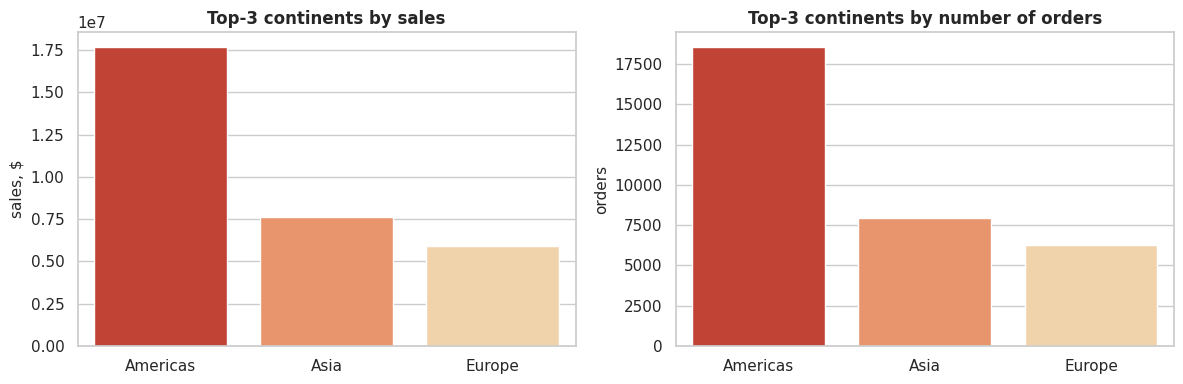

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=top_continents, x='continent', y='sum', ax=axes[0], palette='OrRd_r', hue='continent', legend=False)
axes[0].set_title('Top-3 continents by sales', weight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('sales, $', fontsize=11)

sns.barplot(data=top_continents, x='continent', y='count', ax=axes[1], palette='OrRd_r', hue='continent', legend=False)
axes[1].set_title('Top-3 continents by number of orders', weight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('orders', fontsize=11)

plt.tight_layout()
plt.show()

The continents have a similar share in sales and in the number of orders.

In [ ]:
top_countries = df.groupby('country')['product_price'].agg(['sum', 'count']).sort_values(by='sum', ascending=False).head(5)
top_countries

,sum,count
country,,
United States,13943553.9,14673
India,2809762.0,3029
Canada,2437921.0,2560
United Kingdom,938317.9,1029
France,710692.8,678


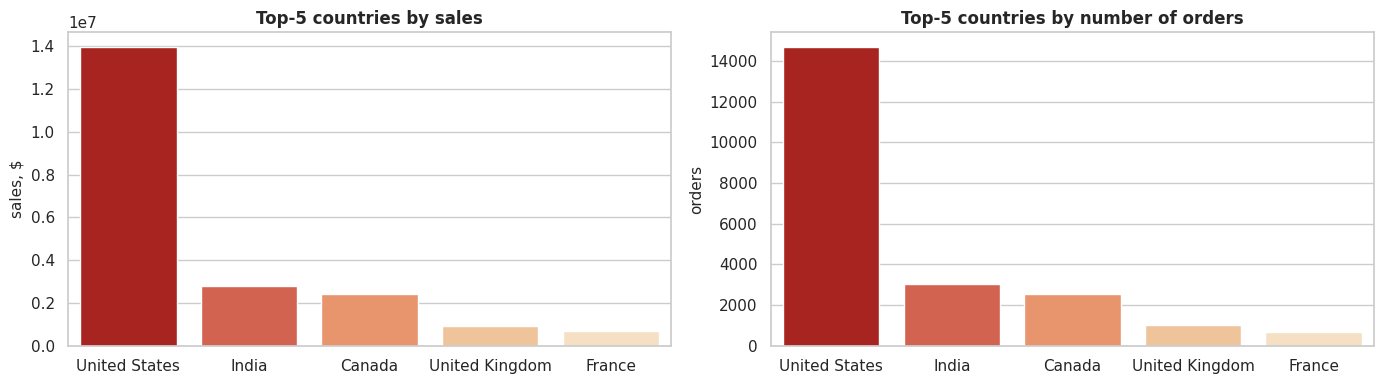

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=top_countries, x='country', y='sum', ax=axes[0], palette='OrRd_r', hue='country', legend=False)
axes[0].set_title('Top-5 countries by sales', weight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('sales, $', fontsize=11)

sns.barplot(data=top_countries, x='country', y='count', ax=axes[1], palette='OrRd_r', hue='country', legend=False)
axes[1].set_title('Top-5 countries by number of orders', weight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('orders', fontsize=11)

plt.tight_layout()
plt.show()

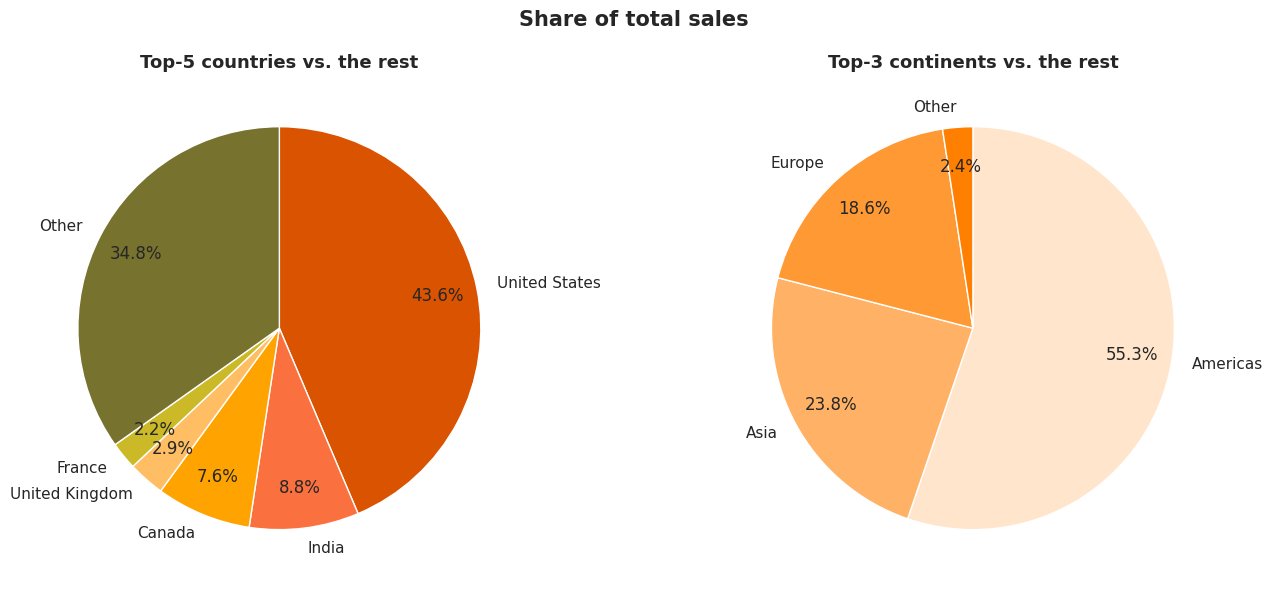

In [ ]:
total = df['product_price'].sum()

shares = top_countries['sum'].copy()
shares['Other'] = total - shares.sum()

shares_cont = top_continents['sum'].copy()
shares_cont['Other'] = total - shares_cont.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

shares.plot(kind='pie', ax=axes[0], autopct='%1.1f%%', startangle=90, colors=green_orng_palette,
                                         counterclock=False, pctdistance=0.8, labeldistance=1.1)
axes[0].set_title('Top-5 countries vs. the rest', fontsize=13, weight='semibold')
axes[0].set_ylabel('')

shares_cont.plot(kind='pie', ax=axes[1], autopct='%1.1f%%', startangle=90,
                   counterclock=False, pctdistance=0.8, labeldistance=1.1)
axes[1].set_title('Top-3 continents vs. the rest', fontsize=13, weight='semibold')
axes[1].set_ylabel('')

fig.suptitle('Share of total sales', fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

In [ ]:
asia = df[df['continent'] == 'Asia']

asia_sales = asia.groupby('country')['product_price'].sum().sort_values(ascending=False)
asia_share = (asia_sales / asia_sales.sum() * 100).round(1)

display(asia_share.head(5))
print(f"India accounts for {asia_share['India']}% of Asia's sales.")

,product_price
country,
India,37.0
China,7.7
Taiwan,7.3
Singapore,6.0
Japan,5.5


India accounts for 37.0% of Asia's sales.


It can be seen that most of Asia’s sales and orders come from India (37% of Asia’s sales). The United States makes up almost half of the total sales (about 44%).

##Share of registered users who unsubscribed

In [ ]:
accounts = df[df['account_id'].notna()].drop_duplicates('account_id')
unsubscribed = accounts['subscription_status'].value_counts(normalize=True) * 100
unsubscribed.round(2)

,proportion
subscription_status,
Subscribed,83.06
Unsubscribed,16.94


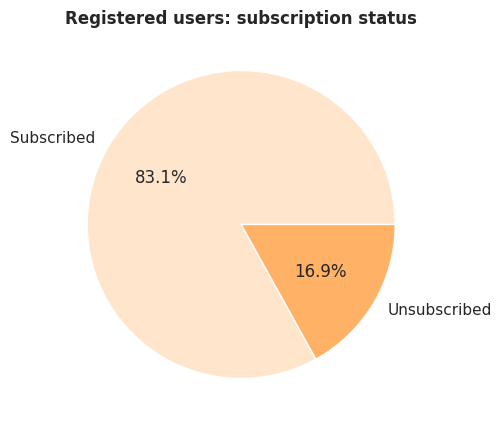

In [ ]:
unsubscribed.plot(kind='pie', autopct='%1.1f%%', figsize=(5, 5))
plt.title('Registered users: subscription status', weight='bold')
plt.ylabel('')
plt.show()

## Do unsubscribed users behave differently in sales?

In [ ]:
registration = df[df['account_id'].notna()]

per_account = registration.groupby(['account_id', 'subscription_status']).agg(orders=('product_price', 'count'),
                                                                 revenue=('product_price', 'sum')).reset_index()
summary = per_account.groupby('subscription_status').agg(users=('account_id', 'nunique'),
                total_sales=('revenue', 'sum'),
                avg_sales_per_user=('revenue', 'mean'),
                avg_orders_per_user=('orders', 'mean'),
                share_with_purchase=('orders', lambda s: (s > 0).mean() * 100))
summary.round(2)

,users,total_sales,avg_sales_per_user,avg_orders_per_user,share_with_purchase
subscription_status,,,,,
Subscribed,23210,2150796.9,92.67,0.10,10.06
Unsubscribed,4735,431721.6,91.18,0.09,9.44


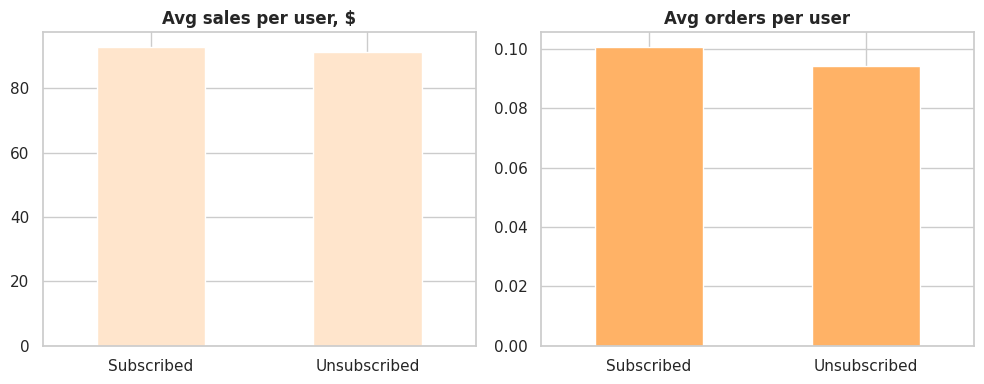

In [ ]:
summary[['avg_sales_per_user', 'avg_orders_per_user']].plot(kind='bar', subplots=True, layout=(1, 2), figsize=(10, 4),
                                         legend=False, rot=0, title=['Avg sales per user, $', 'Avg orders per user'])
for ax in plt.gcf().axes:
    ax.set(xlabel='')
    ax.set_title(ax.get_title(), weight='bold')
plt.tight_layout()
plt.show()

In general, there is no big difference in purchases or in the number of orders between subscribed and unsubscribed users.

## Countries with the most registered users

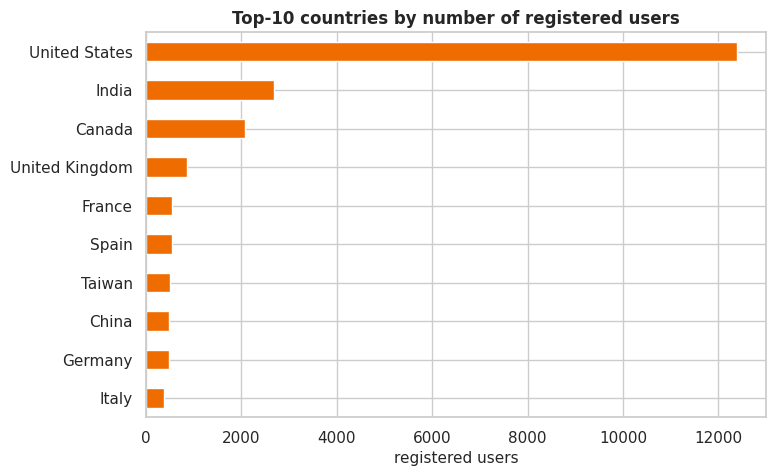

In [ ]:
reg_by_country = registration.groupby('country')['account_id'].nunique().sort_values(ascending=False).head(10)

reg_by_country.plot(kind='barh', figsize=(8, 5), color='#ef6c00')
plt.gca().invert_yaxis()
plt.title('Top-10 countries by number of registered users',weight='bold')
plt.xlabel('registered users', fontsize=11)
plt.ylabel('')
plt.show()

Do users in the USA register more often, or is the number of registered users highest there simply because the USA has the most data? To answer this, the share of registered sessions was compared for the top-10 countries by number of sessions.

In [ ]:
top10 = df.groupby('country')['session_id'].nunique().nlargest(10).index

cntry_data = df[df['country'].isin(top10)].copy()
cntry_data['is_registered'] = cntry_data['account_id'].notna()
reg_share = cntry_data.groupby('country')['is_registered'].mean() * 100

reg_share.round(1).sort_values(ascending=False)

,is_registered
country,
Taiwan,8.5
India,8.2
Spain,8.2
China,8.1
United States,8.1
Canada,8.0
Italy,7.9
Germany,7.9
France,7.9


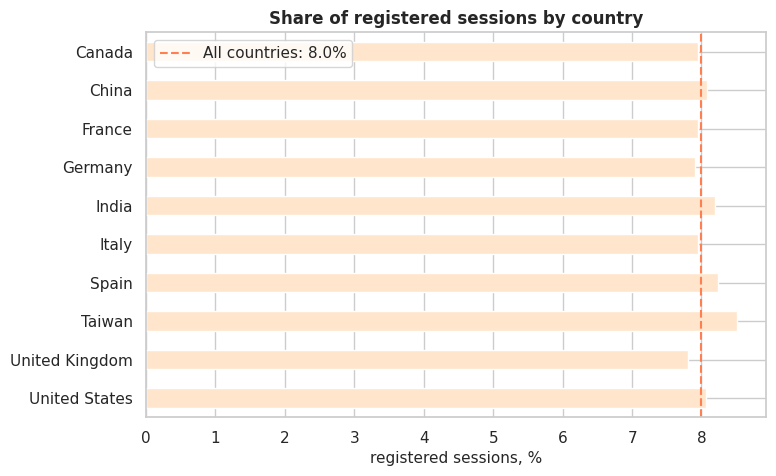

In [ ]:
overall = df['account_id'].notna().mean() * 100

reg_share.plot(kind='barh', figsize=(8, 5), color='#FFE5CC', label='_nolegend_')
plt.axvline(overall, color='coral', linestyle='--', label=f'All countries: {overall:.1f}%')
plt.gca().invert_yaxis()
plt.title('Share of registered sessions by country', weight='bold')
plt.xlabel('registered sessions, %', fontsize=11)
plt.ylabel('')
plt.legend()
plt.show()

The share of registered sessions is almost the same in all top-10 countries: from about 7.8% to 8.5%. The average for all countries is 8.0%. In the USA, the share is also about 8.0%, which is equal to the average.
This means that users in the USA do not register more often than users in other countries. The USA has the most registered users because it has the most sessions overall. The highest share is in Taiwan (about 8.5%), but the difference from the average is small.

# Dynamic analysis

## Total sales per date

In [ ]:
group_date = df.groupby('session_date')['product_price'].sum()
group_date.tail()

,product_price
session_date,
2021-01-27,286340.7
2021-01-28,0.0
2021-01-29,0.0
2021-01-30,0.0
2021-01-31,0.0


In [ ]:
df_sales = df[df['session_date'] <= '2021-01-27'].copy()

The last 4 days (28-31 January 2021) have no sales data, so they were filtered out for the further analysis.

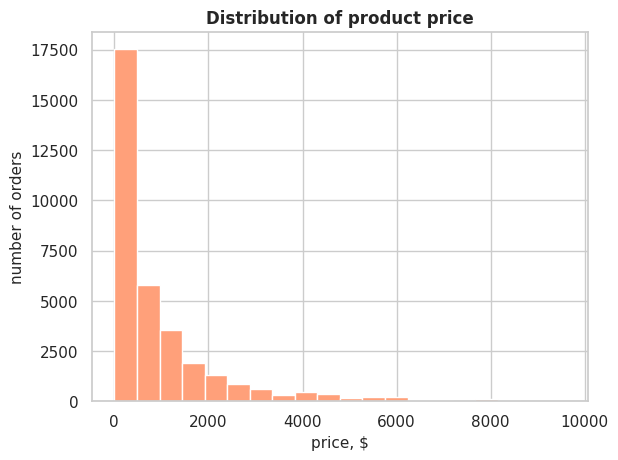

In [ ]:
plt.hist(df_sales['product_price'], bins=20, color='lightsalmon')
plt.title('Distribution of product price', weight='bold')
plt.xlabel('price, $', fontsize=11)
plt.ylabel('number of orders', fontsize=11)
plt.show()

In [ ]:
print(f"Average price:", df_sales['product_price'].mean())
print(f"Median price:", df_sales['product_price'].median())
print(f"Max price:", df_sales['product_price'].max())

Average price: 953.298679110263
Median price: 445.0
Max price: 9585.0


The distribution is not normal: it is strongly right-skewed. Most products have a low price and there is a long tail of expensive products. The mean price (953) is much higher than the median (445).

## Total sales by date

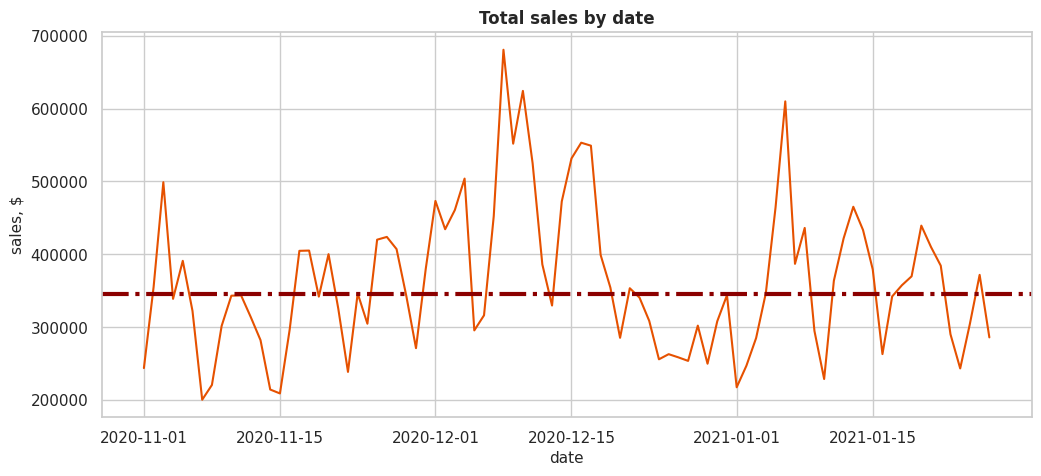

In [ ]:
daily_sales = df_sales.groupby('session_date')['product_price'].sum()

plt.figure(figsize=(12, 5))
sns.lineplot(x=daily_sales.index, y=daily_sales.values, color='#e65100')
plt.title('Total sales by date', weight='bold')
plt.xlabel('date', fontsize=11)
plt.ylabel('sales, $', fontsize=11)
plt.axhline(y=daily_sales.median(), linewidth=3, linestyle='-.', color='#8B0000')
plt.show()

In [ ]:
daily_sales.median()

345354.0

The median stays around 345,000. The highest sales are in the first half of December, and there are also high peaks on 3 November and on 6 January. The lowest period is from 20 December to 3 January, when sales go down to $220,000-300,000. The chart shows a possible pattern: sales are always higher in the first half of each month. This may be related to people receiving their salaries at this time. To test this hypothesis, I will perform a Mann–Whitney U test.

In [ ]:
a = daily_sales[daily_sales.index.day <= 15]
b = daily_sales[daily_sales.index.day > 15]

print(f"1-15: {a.median():.1f},\n16-31: {b.median():.1f}")
print(f"Mann-Whitney: p-value = {mannwhitneyu(a, b).pvalue:.3f}")

1-15: 364010.1,
16-31: 342515.7
Mann-Whitney: p-value = 0.144


Sales tend to be higher in the first half of the month, but the difference between the two periods is not statistically significant. We can not conclude that sales are consistently higher at the beginning of the month.

## Seasonality

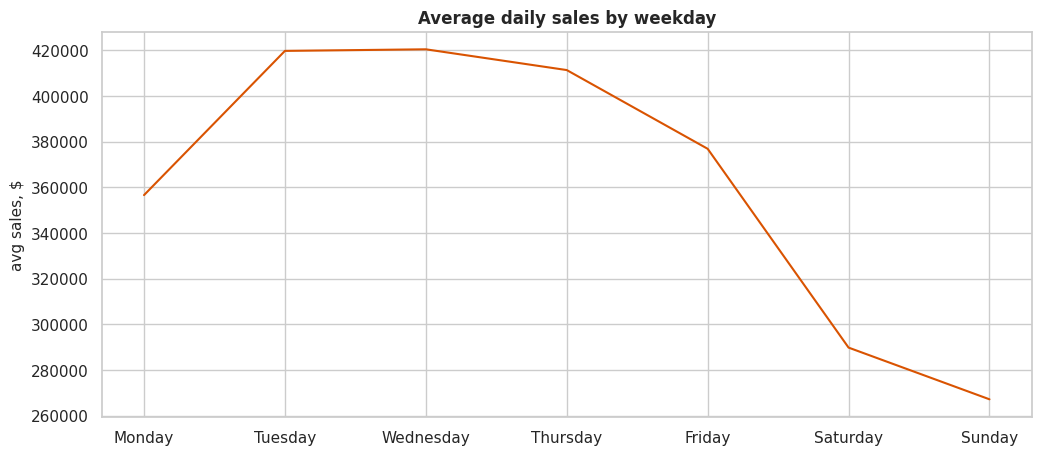

In [ ]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(12, 5))
weekday_sales = daily_sales.groupby(daily_sales.index.day_name()).mean().reindex(order)

sns.lineplot(x=weekday_sales.index, y=weekday_sales.values, color='#d95301')
plt.title('Average daily sales by weekday', weight='bold')
plt.xlabel('')
plt.ylabel('avg sales, $', fontsize=11)
plt.show()

There is a clear weekly pattern. The average sales are the highest on Tuesday and Wednesday (about 420,000) and the lowest on Saturday and Sunday (about 290,000 and 267,000). So the sales on the best weekday are about 55% higher than on Sunday.

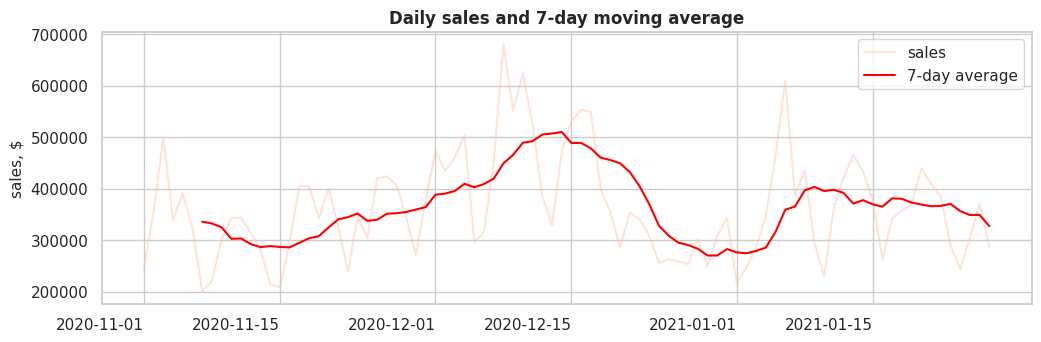

In [ ]:
daily_sales.plot(alpha=0.4, label='sales', figsize=(12, 4), color='#FCBBA1FF', x_compat=True)
daily_sales.rolling(7).mean().plot(label='7-day average', color='red')
plt.xticks(rotation=0)
plt.title('Daily sales and 7-day moving average', weight='bold')
plt.xlabel('')
plt.ylabel('sales, $', fontsize=11)
plt.legend()
plt.show()

The 7-day moving average shows a longer trend: sales grow in December to a peak in the middle of the month, fall at the end of December and the beginning of January, and then recover in January. The growth in December can be connected with the holiday season, and the fall with the holidays themselves. The yearly seasonality cannot be checked without data from other years.

## Sales dynamics by continent

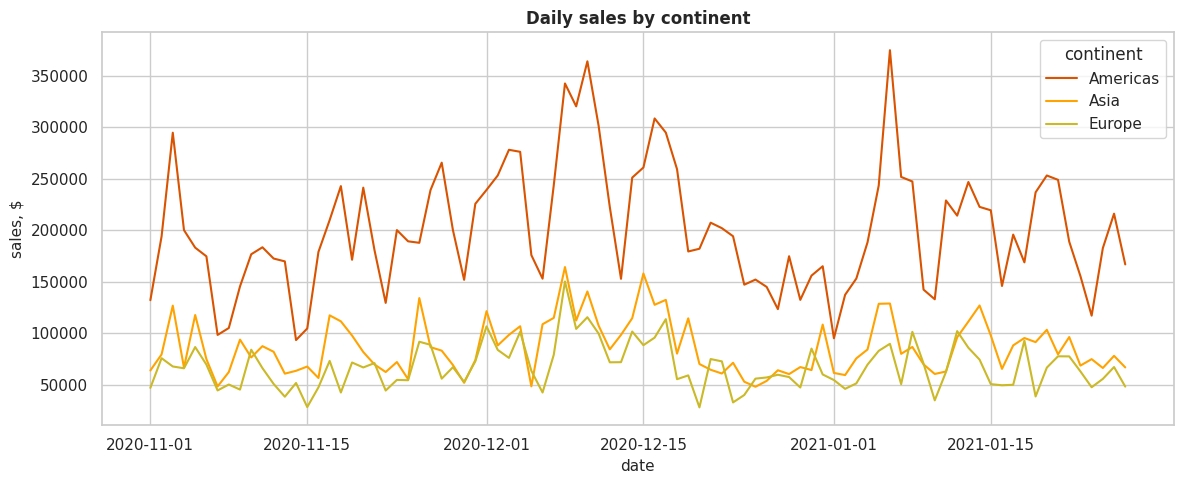

In [ ]:
continent_dynamic = df_sales[df_sales['continent'].isin(['Americas', 'Asia', 'Europe'])].groupby(['session_date', 'continent'])['product_price'].sum().reset_index()

colors = ['#d95301', '#ffa300', '#cbb927']

plt.figure(figsize=(12, 5))
sns.lineplot(data=continent_dynamic, x='session_date', y='product_price', hue='continent', palette=colors)

plt.title('Daily sales by continent', weight='bold')
plt.xlabel('date', fontsize=11)
plt.ylabel('sales, $', fontsize=11)
plt.tight_layout()
plt.show()

The Americas have the highest sales during the whole period (usually 150,000-370,000 per day). Asia and Europe are much lower and are close to each other (about 30,000-160,000), with Asia slightly higher. All three continents have peaks on the same days (for example, in the middle of December and on 6 January). This agrees with the high correlation between them.

## Sales by traffic channel

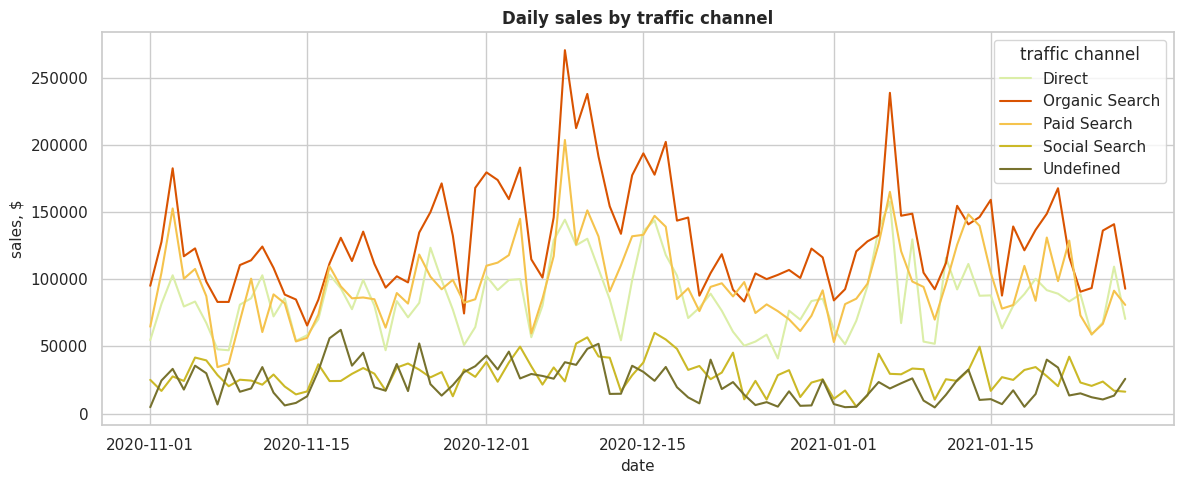

In [ ]:
channel_dynamic = df_sales.groupby(['session_date', 'traffic_channel'])['product_price'].sum().reset_index()

colors2 = ['#DBEEA7', '#d95301', '#F5C34DFF', '#cbb927', '#77722e']
plt.figure(figsize=(12, 5))
sns.lineplot(data=channel_dynamic, x='session_date', y='product_price', hue='traffic_channel', palette=colors2)

plt.title('Daily sales by traffic channel', weight='bold')
plt.xlabel('date', fontsize=11)
plt.ylabel('sales, $', fontsize=11)
plt.legend(title='traffic channel')
plt.tight_layout()
plt.show()

Organic Search gives the highest sales on most days, followed by Paid Search and Direct, which are close to each other. Social Search and Undefined have the lowest sales. All channels go up and down on the same days, so the common peaks are seen in all channels, and there is no channel with its own different trend.

## Sales dynamics by device type

/tmp/ipykernel_9047/3986620698.py:4: UserWarning: The palette list has more values (5) than needed (3), which may not be intended.
  sns.lineplot(data=device_dynamic, x='session_date', y='product_price', hue='device', palette=colors2)


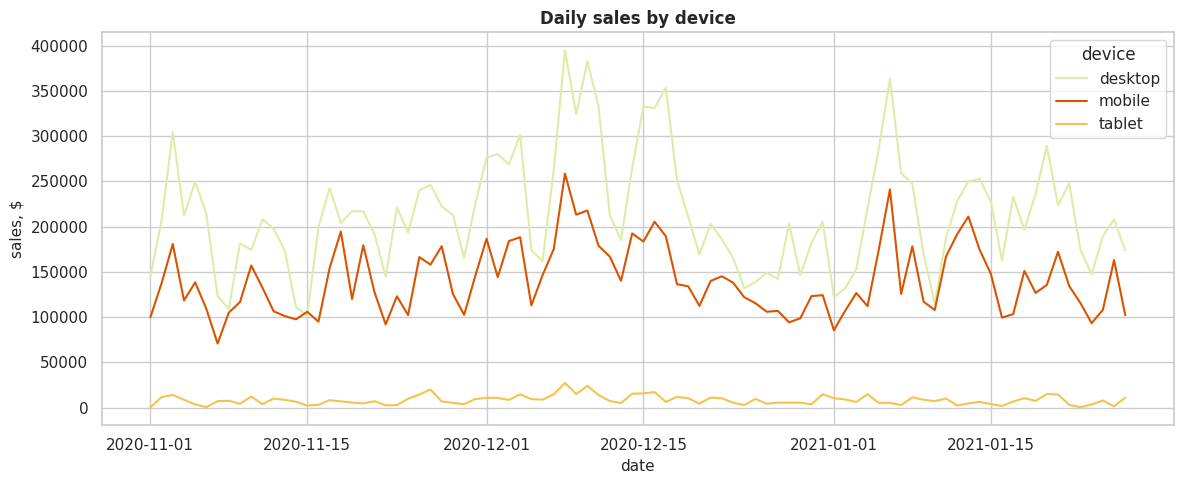

In [ ]:
device_dynamic = df_sales.groupby(['session_date', 'device'])['product_price'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=device_dynamic, x='session_date', y='product_price', hue='device', palette=colors2)

plt.title('Daily sales by device', weight='bold')
plt.xlabel('date', fontsize=11)
plt.ylabel('sales, $', fontsize=11)
plt.tight_layout()
plt.show()

Users on different devices behave in a similar way. The sales of mobile follow the same pattern as desktop, but at a lower level (about two thirds of desktop). Tablet gives very few sales.

## Sessions and Sales by subscription status

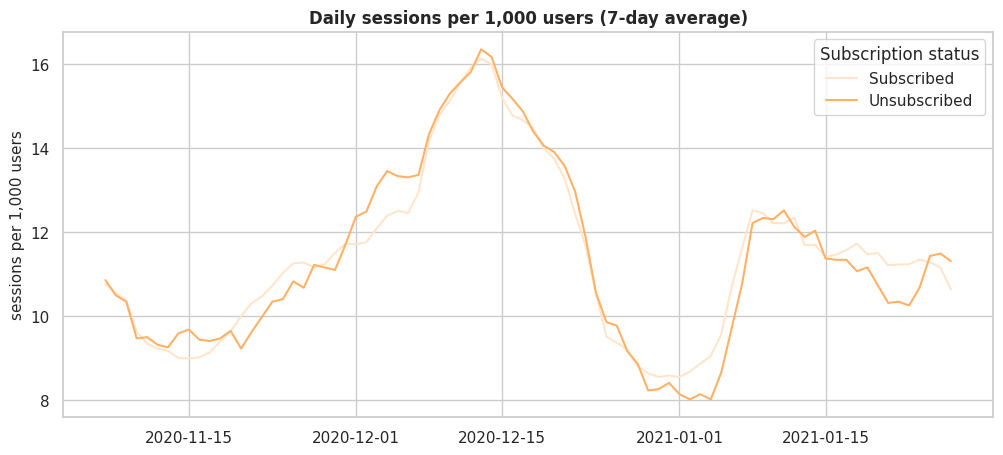

In [ ]:
reg = df_sales[df_sales['account_id'].notna()]
users = reg.groupby('subscription_status')['account_id'].nunique()

sessions_daily = reg.groupby(['session_date', 'subscription_status'])['session_id'].nunique().unstack().fillna(0)
per_1000 = sessions_daily / users * 1000

plt.figure(figsize=(12, 5))
sns.lineplot(data=per_1000.rolling(7).mean(), dashes=False)
plt.title('Daily sessions per 1,000 users (7-day average)', weight='bold')
plt.xlabel('')
plt.ylabel('sessions per 1,000 users', fontsize=11)
plt.legend(title='Subscription status')
plt.show()

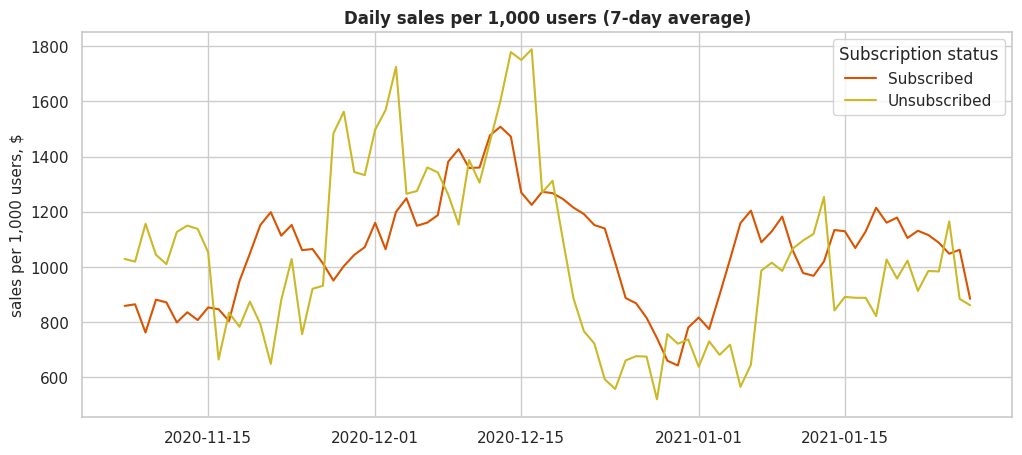

In [ ]:
sales_daily = reg.groupby(['session_date', 'subscription_status'])['product_price'].sum().unstack().fillna(0)
sales_per_1000 = sales_daily / users * 1000

plt.figure(figsize=(12, 5))
sns.lineplot(data=sales_per_1000.rolling(7).mean(), dashes=False, palette=['#d95301', '#cbb927'])

plt.title('Daily sales per 1,000 users (7-day average)', weight='bold')
plt.xlabel('')
plt.ylabel('sales per 1,000 users, $', fontsize=11)
plt.legend(title='Subscription status')
plt.show()

The first comparison showed almost no difference between subscribed and unsubscribed users in average sales (92.67 and 91.18) and in average orders per user. But the averages do not show what happens over time. So the next question was: do subscribed users visit and buy more often than unsubscribed users during the period?

To answer this, two charts were created: daily sessions and daily sales for each group. The groups have different sizes (23,210 subscribed and 4,735 unsubscribed users), so the values were converted to 1,000 users, and the 7-day moving average was used. Only registered users were included, because guests have no subscription status. The days 28-31 January 2021 were excluded.

Conclusion:

The lines of sessions are almost the same for both groups. The activity grows to a peak in the middle of December, falls at the end of December and grows again in January.

The lines of sales have the same general pattern: both groups have a peak in the middle of December (about $1,500-1,800 per 1,000 users) and a fall at the end of December. The line of unsubscribed users is much more unstable, because this group is small, and a few big purchases change the result a lot. It is higher than the subscribed line in some periods (for example, at the beginning of December) and lower in others (at the end of December). There is no period where one group is always better.

This means that the subscription has no stable effect on the activity or on the sales of users. The average values confirm this: the difference in average sales per user is only about 1.6%. The changes in time are probably caused by common factors, such as the holiday season.

There are some limits. The data has no date of unsubscribing, so it is not possible to compare the behavior before and after it. The unsubscribed group is small, so its line is noisy.

In general, the dynamics of sales are very similar in all groups (continents, channels and devices): the peaks and the falls happen on the same days. This means that the main changes are caused by common factors (the day of the week and the holiday season), not by the behavior of a single group. The groups differ mainly in the level of sales: the Americas, Organic Search and desktop are the biggest.

# Pivot tables

## Sessions by traffic channel and device

In [ ]:
print(df['traffic_channel'].unique())
print(df['device'].unique())

['Paid Search' 'Organic Search' 'Direct' 'Undefined' 'Social Search']
['desktop' 'mobile' 'tablet']


In [ ]:
known = df[df['traffic_channel'] != 'Undefined']

pt_sessions = known.pivot_table(index='traffic_channel', columns='device', values='session_id',
                          aggfunc='nunique', fill_value=0, margins=True, margins_name='Total')
pt_sessions.drop(columns='Total').style.background_gradient(cmap='OrRd', axis=None).format('{:,.0f}')

device,desktop,mobile,tablet
traffic_channel,,,
Direct,"47,825","31,745","1,812"
Organic Search,"72,622","49,014","2,789"
Paid Search,"55,167","37,034","2,140"
Social Search,"16,288","10,988",638
Total,"191,902","128,781","7,379"


In [ ]:
mask = df['traffic_channel'] == 'Undefined'
sessions_excl = df.loc[mask, 'session_id'].nunique()

print(f"Sessions excluded: {sessions_excl:,} ({sessions_excl / df['session_id'].nunique() * 100:.1f}%)")

Sessions excluded: 21,483 (6.1%)


In [ ]:
total = pt_sessions.loc['Total', 'Total']

display((pt_sessions['Total'].drop('Total') / total * 100).round(1))
(pt_sessions.loc['Total'].drop('Total') / total * 100).round(1)

,Total
traffic_channel,
Direct,24.8
Organic Search,37.9
Paid Search,28.8
Social Search,8.5


,Total
device,
desktop,58.5
mobile,39.3
tablet,2.2


Sessions with the 'Undefined' channel (21,483, or 6.1%) were excluded. Organic Search brings the most sessions (37.9%), and desktop is the main device (58.5%) in every channel.

## Sales by product category (top-10) and country (top-5)

In [ ]:
top_countries_list = df.groupby('country')['product_price'].sum().nlargest(5).index
top_categories_list = df.groupby('product_category')['product_price'].sum().nlargest(10).index

subset = df[df['country'].isin(top_countries_list) & df['product_category'].isin(top_categories_list)]

pt_sales = subset.pivot_table(index='product_category', columns='country', values='product_price', aggfunc='count', fill_value=0)

pt_sales['Total items sold'] = pt_sales.sum(axis=1)
pt_sales = pt_sales.sort_values('Total items sold', ascending=False)
pt_sales.drop(columns='Total items sold').style.background_gradient(cmap='OrRd', axis=None).format('{:,.0f}')

country,Canada,France,India,United Kingdom,United States
product_category,,,,,
Bookcases & shelving units,591,144,734,232,"3,374"
Chairs,450,116,539,177,"2,576"
Sofas & armchairs,331,91,396,137,"1,903"
Beds,218,56,236,97,"1,298"
Tables & desks,219,60,287,82,"1,248"
Cabinets & cupboards,184,51,201,77,995
Outdoor furniture,177,38,183,65,984
Children's furniture,116,46,142,42,752
Chests of drawers & drawer units,113,32,129,55,616


In [ ]:
sales_table = pt_sales.drop(columns='Total items sold')
country_share = sales_table.sum() / sales_table.values.sum() * 100

country_share.round(1)

,0
country,
Canada,11.6
France,3.1
India,13.8
United Kingdom,4.7
United States,66.8


The United States has about 67% of all orders in this table, so its numbers are much bigger than the numbers of the other countries. However, the structure of categories is similar everywhere. Bookcases & shelving units are the most popular category in all five countries, followed by Chairs and Sofas & armchairs. Bar furniture is the last in all countries.

## Sales by traffic source and account status

In [ ]:
pt_source_status = df.pivot_table(index='traffic_source', columns='account_status', values='product_price',
                              aggfunc='count', fill_value=0, margins=True, margins_name='Total items sold')
pt_source_status.drop(columns='Total items sold', index=['Total items sold']).style.background_gradient(cmap='OrRd', axis=None).format('{:,.0f}')

account_status,Guest,Not verified,Verified
traffic_source,,,
Data deleted,"1,910",55,132
Direct,"7,164",172,464
Organic,"10,446",284,700
Other,"4,419",117,267
Paid (CPC),"1,303",33,71
Referral,"5,515",131,355


As it was calculated earlier, guests make about 92% of the orders in every traffic source. Organic is the biggest source of orders, followed by Direct and Referral. Paid (CPC) gives the smallest number in every group, but it also has the fewest sessions.

## Monthly sales by continent

In [ ]:
df_sales['month'] = df_sales['session_date'].dt.strftime('%Y-%m')

pt_month = df_sales[df_sales['continent'].isin(['Americas', 'Asia', 'Europe'])].pivot_table(index='month',
                   columns='continent', values='product_price', aggfunc='sum', fill_value=0)
pt_month.round(0).style.background_gradient(cmap='OrRd', axis=None).format('{:,.0f}')

continent,Americas,Asia,Europe
month,,,
2020-11,"5,439,028","2,393,235","1,825,299"
2020-12,"6,854,446","2,905,400","2,349,628"
2021-01,"5,371,806","2,302,664","1,759,698"


December is the peak month in all continents, and the Americas lead every month. January looks lower, but only 27 days of order data are available for this month. It's not possible to say that this is real seasonality without data for the previous year.

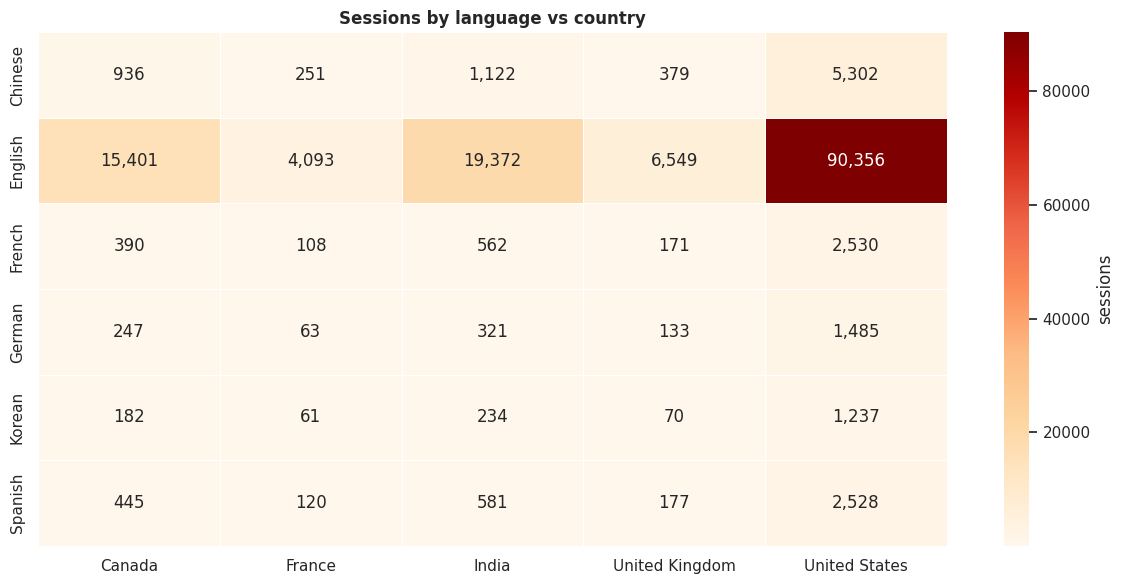

In [ ]:
known = df[df['browser_language_name'] != 'Unknown']

top_langs = known.groupby('browser_language_name')['session_id'].nunique().nlargest(6).index
subset = known[known['country'].isin(top_countries.index) & known['browser_language_name'].isin(top_langs)]
pt_lang_country = subset.pivot_table(index='browser_language_name', columns='country', values='session_id',
                                      aggfunc='nunique', fill_value=0, margins=True, margins_name='Total')

heat = pt_lang_country.drop(index='Total', columns='Total')

plt.figure(figsize=(12, 6))
sns.heatmap(heat, annot=True, fmt=',d', cmap='OrRd', linewidths=0.5, cbar_kws={'label': 'sessions'})
plt.title('Sessions by language vs country', weight='bold')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [ ]:
heat_pct = heat / heat.sum() * 100
heat_pct.round(1)

country,Canada,France,India,United Kingdom,United States
browser_language_name,,,,,
Chinese,5.3,5.3,5.1,5.1,5.1
English,87.5,87.2,87.3,87.6,87.4
French,2.2,2.3,2.5,2.3,2.4
German,1.4,1.3,1.4,1.8,1.4
Korean,1.0,1.3,1.1,0.9,1.2
Spanish,2.5,2.6,2.6,2.4,2.4


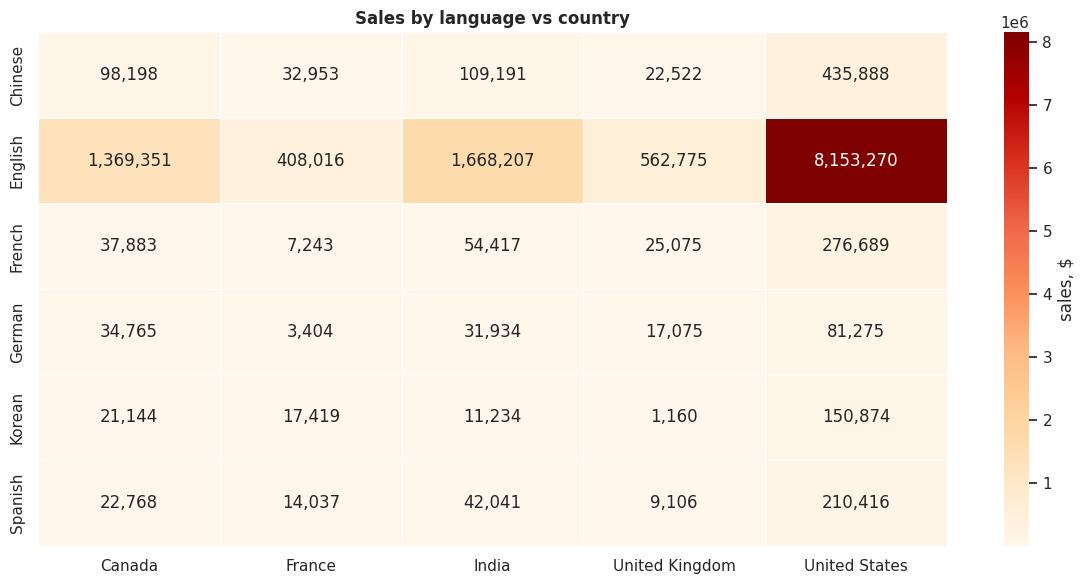

In [ ]:
top_sales = known.groupby('browser_language_name')['product_price'].sum().nlargest(6).index

subset_1 = known[known['country'].isin(top_countries.index) & known['browser_language_name'].isin(top_sales)]
pt_lang_country = subset_1.pivot_table(index='browser_language_name', columns='country', values='product_price',
                                               aggfunc='sum', fill_value=0, margins=True, margins_name='Total')

heat = pt_lang_country.drop(index='Total', columns='Total')
plt.figure(figsize=(12, 6))
sns.heatmap(heat, annot=True, fmt=',.0f', cmap='OrRd', linewidths=0.5, cbar_kws={'label': 'sales, $'})
plt.title('Sales by language vs country', weight='bold')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [ ]:
pt_lang_country['Total'] / pt_lang_country.loc['Total', 'Total'] * 100

,Total
browser_language_name,
Chinese,5.016049
English,87.303154
French,2.880818
German,1.209258
Korean,1.448866
Spanish,2.141855
Total,100.000000


In [ ]:
pt_lang_country.loc['Total'] / pt_lang_country.loc['Total', 'Total'] * 100

,Total
country,
Canada,11.371658
France,3.467768
India,13.761517
United Kingdom,4.577870
United States,66.821186
Total,100.000000


Sessions with an unknown language were excluded. In all five countries, English is the main browser language: it makes about 87% of the sessions with a known language. The United States has the most sessions of every language (for example, 90,356 'english' sessions), but the reason is the USA has the most traffic overall.
The language structure is almost the same in all countries: about 87% English, about 5% Chinese, about 2% French, 2% Spanish, 1% German and 1% Korean. For example, French is 2.3% of the sessions in France and 2.4% in the USA. The sales by language show the same picture: English gives 87% of the sales in the table, and the USA gives 67%.
This result is unusual, because the language of a browser normally depends on the country. It means that the browser language in this dataset does not help to separate the countries, and the main difference between them is the volume of traffic.

The tables overview show that the main differences are in volume, not in behavior, and the structure of sales is stable. The segment share is almost the same in all channels and countries. The USA, the Americas and Organic Search are the biggest groups, and December is the peak month.

# Statistical Analysis of Correlation

## Sessions and sales

In [ ]:
daily = df_sales.groupby('session_date').agg(sessions=('session_id', 'nunique'), sales=('product_price', 'sum'))
daily

,sessions,sales
session_date,,
2020-11-01,2576,244292.5
2020-11-02,3599,355506.8
2020-11-03,5173,498979.6
2020-11-04,4184,339187.1
2020-11-05,3743,391276.6
...,...,...
2021-01-23,3067,290605.5
2021-01-24,2893,243818.4
2021-01-25,3760,305089.3


In [ ]:
print("P-value, sessions:", shapiro(daily['sessions'])[1])
print("P-value, sales:", shapiro(daily['sales'])[1])

P-value, sessions: 0.03948838648168485
P-value, sales: 0.0047925668386651875


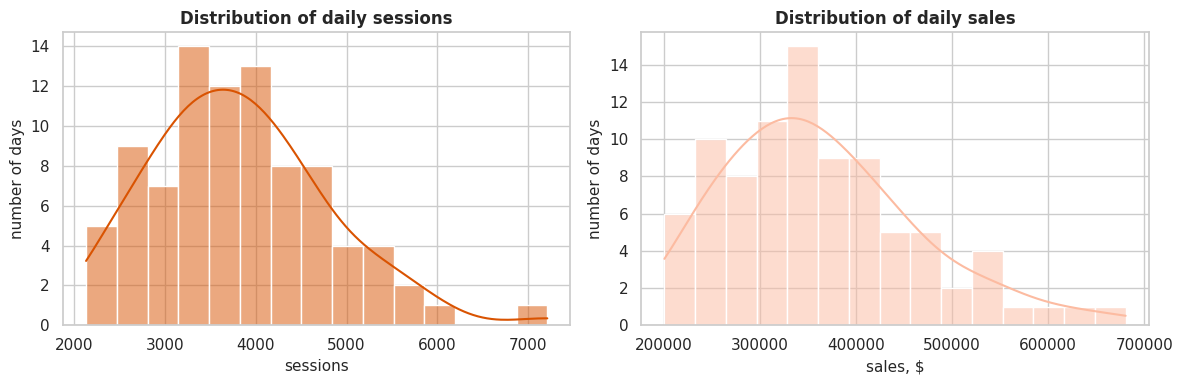

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(daily['sessions'], kde=True, bins=15, color='#d95301', ax=axes[0])
axes[0].set_title('Distribution of daily sessions', weight='bold')
axes[0].set_xlabel('sessions', fontsize=11)
axes[0].set_ylabel('number of days', fontsize=11)

sns.histplot(daily['sales'], kde=True, bins=15, color='#FCBBA1FF', ax=axes[1])
axes[1].set_title('Distribution of daily sales', weight='bold')
axes[1].set_xlabel('sales, $', fontsize=11)
axes[1].set_ylabel('number of days',fontsize=11)

plt.tight_layout()
plt.show()

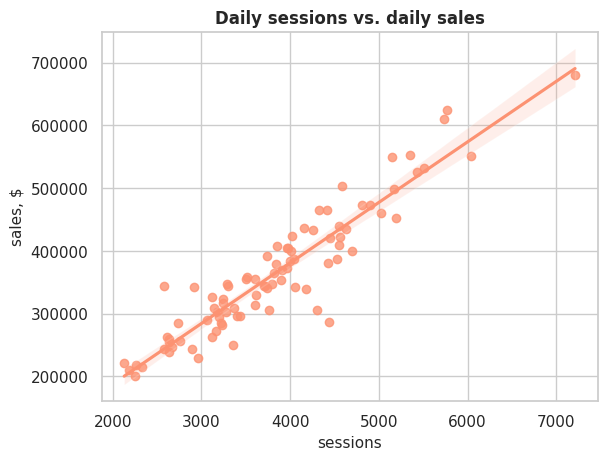

In [ ]:
sns.regplot(data=daily, x='sessions', y='sales', color='#FC9272FF')
plt.title('Daily sessions vs. daily sales', weight='bold')
plt.xlabel('sessions', fontsize=11)
plt.ylabel('sales, $', fontsize=11)
plt.show()

In [ ]:
spearman_r, spearman_p = spearmanr(daily['sessions'], daily['sales'])
pearson_r, pearson_p = pearsonr(daily['sessions'], daily['sales'])

print(f"Spearman: rho = {spearman_r:.3f}, p-value = {spearman_p:.2e}")
print(f"Pearson:  r = {pearson_r:.3f}, p-value = {pearson_p:.2e}")

Spearman: rho = 0.904, p-value = 1.54e-33
Pearson:  r = 0.931, p-value = 1.74e-39


The Shapiro-Wilk test showed that daily sessions and daily sales are not normal (p = 0.039 and p = 0.005), so Spearman’s coefficient was chosen as the main one. There is a strong positive correlation between daily sessions and daily sales (rho = 0.904, p < 0.001). Pearson’s coefficient gives a similar result (r = 0.931). This means that on days with more sessions, sales are usually higher. The days 28-31 January 2021 were excluded, because order data is missing for them. The correlation does not prove that sessions cause sales.

## Correlation by Continents

In [ ]:
from itertools import combinations

def corr_pairs(table):
    rows = []
    for a, b in combinations(table.columns, 2):
        r, p = spearmanr(table[a], table[b])
        rows.append({'pair': f'{a} - {b}', 'r': round(r, 3), 'p_value': f'{p:.2e}', 'significant': p < 0.05})
    return pd.DataFrame(rows)

cont_daily = df_sales[df_sales['continent'].isin(['Americas', 'Asia', 'Europe'])].pivot_table(index='session_date',
                                         columns='continent', values='product_price', aggfunc='sum', fill_value=0)

corr_pairs(cont_daily)

,pair,r,p_value,significant
0,Americas - Asia,0.669,1.10e-12,True
1,Americas - Europe,0.626,7.01e-11,True
2,Asia - Europe,0.608,3.27e-10,True


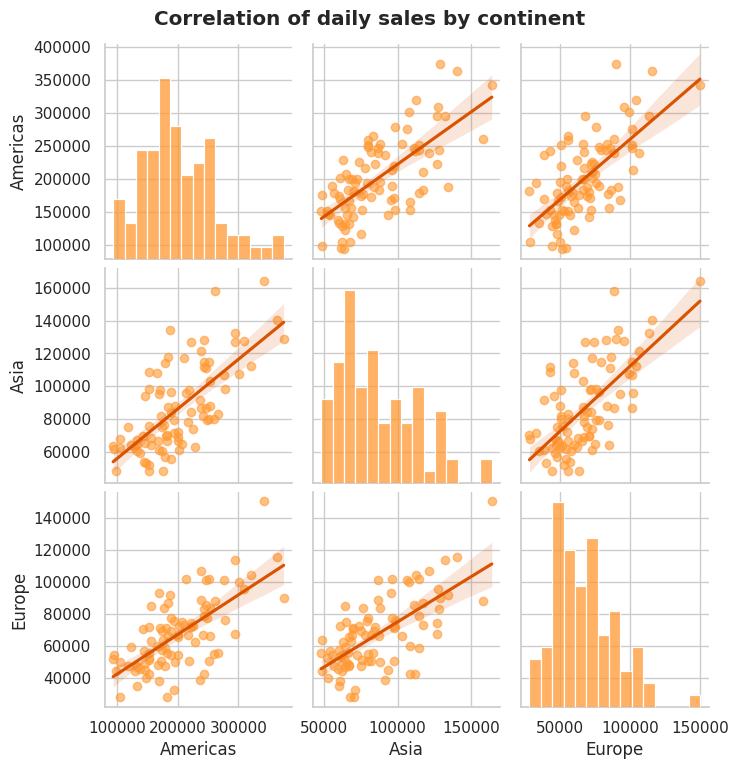

In [ ]:
pair = sns.pairplot(cont_daily, kind='reg', diag_kind='hist',
                 plot_kws={'line_kws': {'color': '#d95301'}, 'scatter_kws': {'color': '#FF9933', 'alpha': 0.6}},
                 diag_kws={'color': '#FF9933', 'bins': 15})
pair.figure.suptitle('Correlation of daily sales by continent', weight='bold', y=1.02)
plt.show()

Daily sales in the three top continents are positively correlated, and all the correlations are statistically significant (p < 0.001): Americas - Asia (r = 0.669), Americas - Europe (r = 0.626) and Asia - Europe (r = 0.608). The strength is moderate to strong, and the values are very close to each other. This means that sales in all continents go up and down on the same days. Possible reasons are common factors, such as weekdays, holidays or promotions, but the data cannot confirm this.

In [ ]:
ch_daily = df_sales[df_sales['traffic_channel'] != 'Undefined'].pivot_table(index='session_date',
                 columns='traffic_channel', values='product_price', aggfunc='sum', fill_value=0)

corr_pairs(ch_daily)

,pair,r,p_value,significant
0,Direct - Organic Search,0.748,5.36e-17,True
1,Direct - Paid Search,0.691,9.51e-14,True
2,Direct - Social Search,0.394,1.48e-04,True
3,Organic Search - Paid Search,0.764,4.86e-18,True
4,Organic Search - Social Search,0.385,2.14e-04,True
5,Paid Search - Social Search,0.420,4.54e-05,True


In [ ]:
ch_daily

traffic_channel,Direct,Organic Search,Paid Search,Social Search
session_date,,,,
2020-11-01,54669.5,95112.0,64688.0,25078.0
2020-11-02,81561.5,127746.5,104780.8,16843.0
2020-11-03,102909.5,182521.9,152641.3,27652.5
2020-11-04,79683.6,117067.1,100332.0,24257.4
2020-11-05,83367.6,122938.4,107648.0,41693.2
...,...,...,...,...
2021-01-23,88714.4,90686.0,73075.1,23095.0
2021-01-24,58644.2,93413.6,59018.0,20596.1
2021-01-25,67844.0,136178.6,66775.7,23809.0


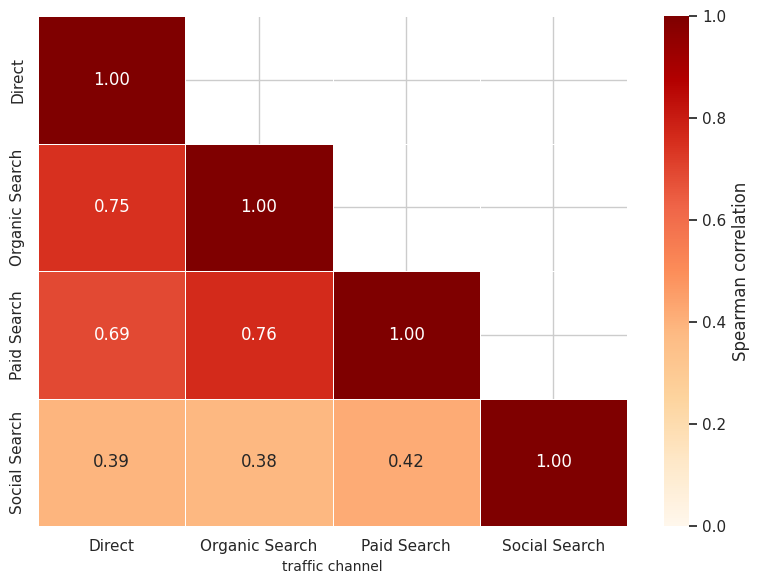

In [ ]:
corr = ch_daily.corr(method='spearman')
mask_ch = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(8, 6))
sns.heatmap(ch_daily.corr(method='spearman'), mask=mask_ch, annot=True, fmt='.2f', cmap='OrRd',
            vmin=0, vmax=1, linewidths=0.5, cbar_kws={'label': 'Spearman correlation'})
plt.xlabel('traffic channel', fontsize=10)
plt.ylabel('')
plt.tight_layout()

All pairs of channels show a significant positive correlation (p < 0.001). The strongest relationships are Organic Search - Paid Search (r = 0.764), Direct - Organic Search (r = 0.748) and Direct - Paid Search (r = 0.691). Social Search is correlated with the other channels more weakly (r = 0.385-0.420). This means that Social Search sales follow their own pattern more than the other channels.

## Top-5 product categories

In [ ]:
top5_category = df_sales.groupby('product_category')['product_price'].sum().nlargest(5).index

c_daily = df_sales[df_sales['product_category'].isin(top5_category)].pivot_table(index='session_date',
                   columns='product_category', values='product_price', aggfunc='sum', fill_value=0)

corr_pairs(c_daily)

,pair,r,p_value,significant
0,Beds - Bookcases & shelving units,0.543,4.69e-08,True
1,Beds - Cabinets & cupboards,0.440,1.76e-05,True
2,Beds - Chairs,0.535,7.91e-08,True
3,Beds - Sofas & armchairs,0.522,1.86e-07,True
4,Bookcases & shelving units - Cabinets & cupboards,0.529,1.19e-07,True
5,Bookcases & shelving units - Chairs,0.637,2.59e-11,True
6,Bookcases & shelving units - Sofas & armchairs,0.626,7.19e-11,True
7,Cabinets & cupboards - Chairs,0.527,1.34e-07,True
8,Cabinets & cupboards - Sofas & armchairs,0.631,4.32e-11,True
9,Chairs - Sofas & armchairs,0.583,2.46e-09,True


In [ ]:
c_daily

product_category,Beds,Bookcases & shelving units,Cabinets & cupboards,Chairs,Sofas & armchairs
session_date,,,,,
2020-11-01,14041.0,36701.0,13591.5,46006.0,75216.0
2020-11-02,79683.5,40979.0,21623.0,58834.0,79977.5
2020-11-03,66219.5,64360.1,33555.5,61204.0,175594.0
2020-11-04,48939.0,35719.8,19266.0,44113.0,86861.5
2020-11-05,23449.0,40998.8,29235.0,90388.4,137288.0
...,...,...,...,...,...
2021-01-23,37116.0,29862.7,26068.0,57493.0,76898.0
2021-01-24,23294.0,25396.0,23664.5,54288.0,57837.0
2021-01-25,47303.5,25919.6,33028.0,51424.2,84544.0


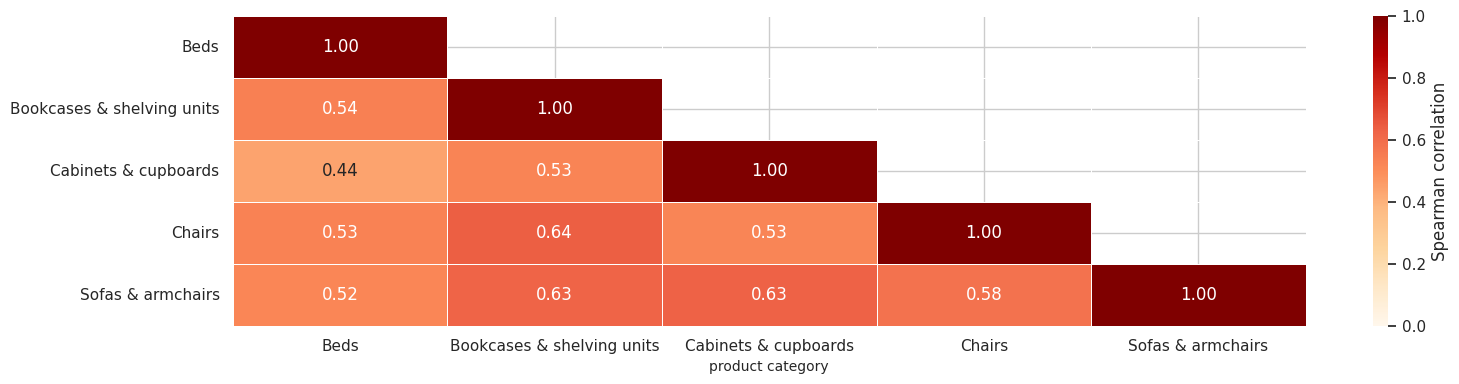

In [ ]:
corr = c_daily.corr(method='spearman')
mask_c = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(16, 4))
sns.heatmap(c_daily.corr(method='spearman'), mask=mask_c, annot=True, fmt='.2f', cmap='OrRd',
            vmin=0, vmax=1, linewidths=0.5, cbar_kws={'label': 'Spearman correlation'})
plt.xlabel('product category', fontsize=10)
plt.ylabel('')
plt.tight_layout()

Daily sales of the top-5 categories (Beds, Bookcases & shelving units, Cabinets & cupboards, Chairs, Sofas & armchairs) are positively correlated, and all the correlations are significant (p < 0.001). The correlation strength is moderate (r = 0.440-0.637). The strongest relationship is Bookcases & shelving units - Chairs (r = 0.637), and the weakest is Beds - Cabinets & cupboards (r = 0.440). Customers buy different categories on the same days, but the categories are not fully dependent on each other.

In all tests the correlations are positive and significant. Part of these relationships can be explained by common daily factors, such as total traffic. Spearman's coefficient was used in all tests, because daily sales are not normal.

# Statistical Analysis of Group Differences

## Registered vs Not registered users

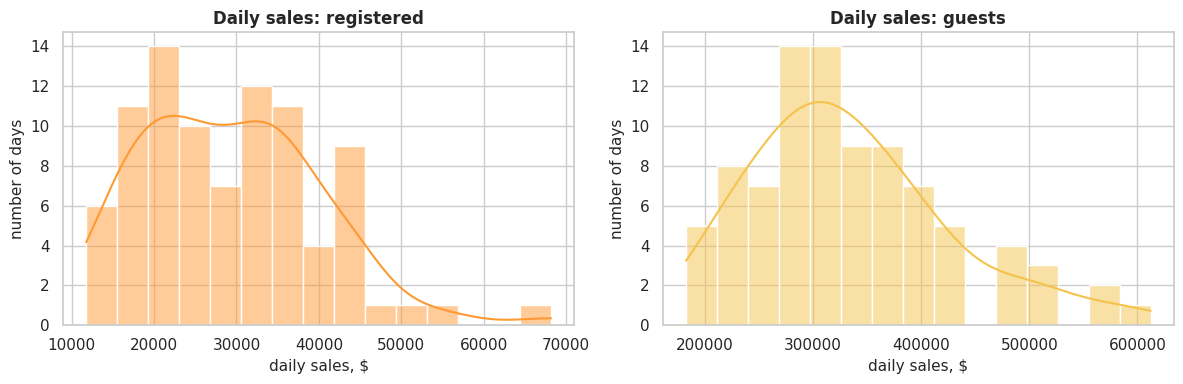

Shapiro p-value, registered: 0.007295139880540744
Shapiro p-value, guests: 0.0026183359245325936


In [ ]:
sales_by_group = df_sales.assign(group=np.where(df_sales['account_id'].notna(), 'Registered', 'Guest')).pivot_table(index='session_date',
                                                                   columns='group', values='product_price', aggfunc='sum', fill_value=0)

registered = sales_by_group['Registered']
guest = sales_by_group['Guest']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(registered, kde=True, bins=15, color='#FF9933', ax=axes[0])
axes[0].set_title('Daily sales: registered', weight='bold')
axes[0].set_xlabel('daily sales, $', fontsize=11)
axes[0].set_ylabel('number of days', fontsize=11)

sns.histplot(guest, kde=True, bins=15, color='#F5C34DFF', ax=axes[1])
axes[1].set_title('Daily sales: guests', weight='bold')
axes[1].set_xlabel('daily sales, $', fontsize=11)
axes[1].set_ylabel('number of days', fontsize=11)

plt.tight_layout()
plt.show()

print("Shapiro p-value, registered:", shapiro(registered)[1])
print("Shapiro p-value, guests:", shapiro(guest)[1])

In [ ]:
w, p_w = wilcoxon(registered, guest)
print(f"Wilcoxon: W = {w:.0f}, p-value = {p_w:.2e}")
print(f"Median, registered: {registered.median():,.0f}")
print(f"Median, guests: {guest.median():,.0f}")

Wilcoxon: W = 0, p-value = 3.73e-16
Median, registered: 28,048
Median, guests: 316,724


In [ ]:
sessions_by_group = df_sales.assign(group=np.where(df_sales['account_id'].notna(), 'Registered', 'Guest')).pivot_table(index='session_date',
                                                                                    columns='group', values='session_id', aggfunc='nunique')

per_session = sales_by_group / sessions_by_group
diff = per_session['Registered'] - per_session['Guest']

In [ ]:
per_session

group,Guest,Registered
session_date,,
2020-11-01,94.987420,93.277056
2020-11-02,94.077552,150.861745
2020-11-03,99.497903,64.635255
2020-11-04,82.715077,62.261721
2020-11-05,106.440372,83.064262
...,...,...
2021-01-23,97.301843,65.516260
2021-01-24,84.883625,78.329588
2021-01-25,78.826157,105.770279


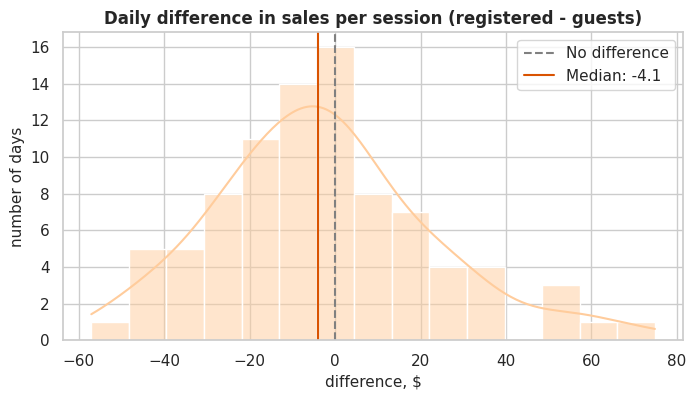

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(diff, kde=True, bins=15, color='#ffcc9c')
plt.axvline(0, color='gray', linestyle='--', label='No difference')
plt.axvline(diff.median(), color='#d95301', label=f'Median: {diff.median():.1f}')
plt.title('Daily difference in sales per session (registered - guests)', weight='bold')
plt.xlabel('difference, $', fontsize=11)
plt.ylabel('number of days', fontsize=11)
plt.legend()
plt.show()

In [ ]:
w, p = wilcoxon(per_session['Registered'], per_session['Guest'])
print(f"Wilcoxon: W = {w:.0f}, p-value = {p:.3f}")
print(f"Days when registered > guests: {(diff > 0).sum()} of {len(diff)}")

Wilcoxon: W = 1598, p-value = 0.134
Days when registered > guests: 35 of 88


In [ ]:
per_session.median()

,0
group,
Guest,94.852072
Registered,90.835529


Total daily sales are much higher for guests than for registered users. But this is because guests make up about 92% of all sessions. So sales per session were compared.
The registered users and the guests are observed on the same days, so the samples are paired. The histogram of the daily differences is close to symmetric, with the center near zero, so I used the Wilcoxon signed-rank test instead of the Mann-Whitney U test.
The difference is not statistically significant (W = 1598, p = 0.134). The median sales per session are 90.8 for registered users and 94.9 for guests. Registered users spent more on only 35 of 88 days. This means it can not be said that registered users spend more (or less) per session than guests.

## Sessions by traffic channel

In [ ]:
ch_sessions = df[df['traffic_channel'] != 'Undefined'].pivot_table(index='session_date',
        columns='traffic_channel', values='session_id', aggfunc='nunique', fill_value=0)
for col in ch_sessions:
    print(col, round(shapiro(ch_sessions[col])[1], 4))

chi, p = friedmanchisquare(*[ch_sessions[c] for c in ch_sessions.columns])
print(f"Friedman: chi-square = {chi:.2f}, p-value = {p:.2e}")

Direct 0.0343
Organic Search 0.0123
Paid Search 0.0108
Social Search 0.1413
Friedman: chi-square = 276.00, p-value = 1.55e-59


In [ ]:
ch_sessions

traffic_channel,Direct,Organic Search,Paid Search,Social Search
session_date,,,,
2020-11-01,608,920,706,214
2020-11-02,810,1242,970,315
2020-11-03,1216,1871,1367,392
2020-11-04,935,1425,1145,368
2020-11-05,845,1293,917,346
...,...,...,...,...
2021-01-27,984,1561,1192,359
2021-01-28,997,1379,1107,364
2021-01-29,878,1319,988,288


In [ ]:
ch_sessions.median()

,0
traffic_channel,
Direct,869.5
Organic Search,1329.0
Paid Search,989.0
Social Search,308.0


I compared the number of daily sessions between four traffic channels: Direct, Organic Search, Paid Search and Social Search. Sessions with the 'Undefined' channel were excluded, because their source is unknown.
I used the full dataset (all 92 days). The missing data for 28-31 January 2021 is about orders, not sessions. The number of sessions for these days is normal, so there is no reason to remove them.

The same days are used for all channels, so the samples are paired. Because of this, I used the Friedman test instead of the Kruskal-Wallis test.
The result is statistically significant (chi-square = 276.00, p < 0.001). This means that at least one channel has a different number of daily sessions. The medians show that Organic Search has the most sessions (1,329 per day), and Social Search has the fewest (308 per day). The value of chi-square is the maximum possible for 92 days, so the order of the channels was the same every day.

## % of organic traffic: Europe vs Americas

In [ ]:
subreg = df[df['continent'].isin(['Europe', 'Americas'])].copy()
subreg['is_organic'] = subreg['traffic_channel'] == 'Organic Search'

organic = subreg.groupby('continent')['is_organic'].agg(organic='sum', total='count')
organic['share, %'] = organic['organic'] / organic['total'] * 100
organic

,organic,total,"share, %"
continent,,,
Americas,68671,193179,35.547860
Europe,23195,65135,35.610655


In [ ]:
z, p = proportions_ztest(organic['organic'], organic['total'])
print(f"z = {z:.2f}, p-value = {p:.2e}")

z = -0.29, p-value = 7.72e-01


The share of organic traffic in Europe and the Americas was compared. The input data for the test is the number of organic sessions and the total number of sessions for each continent.
The share of organic sessions is 35.55% in the Americas (68,671 of 193,179) and 35.61% in Europe (23,195 of 65,135). The difference is only 0.06 percentage points.
I used the z-test for two proportions, because two shares are compared and the samples are large and independent. The difference is not statistically significant (z = -0.29, p = 0.77). This means there is no evidence that the share of organic traffic is different in these two continents. In practice, the shares are almost the same.

#Business conclusions

### What the data shows
The dataset covers 92 days (1 November 2020 - 31 January 2021): 349,545 sessions and 33,538 orders (about 9.6% of sessions). The total sales are about \$32 million, and the typical order is small (median \$445, mean \$953).
The USA is the core market (about 44% of sales). The Americas give 55% of sales, Asia 24% (mostly India) and Europe 19%. The structure of products is the same in all countries: Bookcases, Chairs and Sofas are the most ordered categories everywhere.
Sales follow traffic: daily sessions and sales have a strong correlation (rho = 0.90). The conversion is almost the same in all traffic sources (9.2-9.8%), on all devices and for all users, so growth mainly depends on the number of sessions.
Organic Search is the largest channel (38% of sessions with a known channel). Desktop gives 58% of sessions and more sales than mobile, but mobile has a similar conversion. Tablet is marginal (2%).
Guests make about 92% of sessions and orders. Registered users do not spend more per session than guests (difference not significant, p = 0.134). Unsubscribed users (17% of registered users) buy and visit as often as subscribed ones.
Sales have a clear weekly pattern: Tuesday and Wednesday are the best days, and weekends are 30-36% lower. December has the peak, and 20 December - 3 January is the lowest period. All continents, channels and devices show the same pattern, so the changes are caused by common factors, not by one segment.

###Recommendations

* Focus on traffic growth, first of all in Organic Search.
* Plan promotions and events around the season: prepare for early and middle December, and use offers to support weak weekend days.
* Do not expect the mailing list or registration alone to raise sales. Test it with an A/B experiment before investing more.
* Keep one assortment and one message for all key markets, and look at India as a growth market inside Asia.
* Improve tracking: 6% of sessions have an undefined channel, about one third have no language, and order data is missing for 28-31 January.

In [ ]:
from google.colab import files

df.to_csv('sessions_clean.csv', index=False)
files.download('sessions_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>